# RL post-training: from an LLM judge to RLAIF and RLHF

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/somilsin/Machine-Learning/blob/main/Transformers_Large-Language-Models/3_RL_Post_Training.ipynb)

In this notebook I run my two RL post-training projects end to end:

* **Part A · RLAIF.** I turn the Yoda-style judge from my [2_LLM_Finetuning.ipynb](2_LLM_Finetuning.ipynb) into a reward model. It labels preference pairs for DPO (offline) and scores rollouts live for GRPO (online).
* **Part B · RLHF.** I go through the classic pipeline: supervised fine-tuning on human-preferred replies, a Bradley-Terry reward model from human preferences and GRPO against it. Then I reuse the same RL loop with a verifiable reward: a GSM8K answer checker.

I kept every training loop in plain PyTorch instead of using TRL. Each file is written with `%%writefile` right before the step that uses it so I can read the code beside its results.

**How I run it:** Runtime → Change runtime type → **T4 GPU**. `QUICK = True` is my first pass with small settings and `QUICK = False` uses the full settings. Everything in `runs/` disappears when the Colab session ends. The last cell can copy the logs to Drive.

**Execution record:** executed end to end on a Colab Tesla T4 (15 GB) on 22 October 2026 with `QUICK = True`. All outputs below are from that run. QUICK runs are small (40 RL steps, 30-100 evaluation prompts) so differences of a few points are within noise.

## 0 · Setup

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [2]:
import os
os.makedirs("/content/rl-post-training/rlaif_yoda", exist_ok=True)
os.makedirs("/content/rl-post-training/rlhf_hh", exist_ok=True)
%cd /content/rl-post-training
!pip install -q "transformers>=4.56,<5" "peft>=0.13" "datasets>=2.19" accelerate "setuptools<81" wheel
!pip install -q mitdeeplearning --no-deps --no-build-isolation
# note to self: Colab ships an old torchao that current peft refuses to import. Removing it fixes that.
!pip uninstall -q -y torchao

/content/rl-post-training
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 63.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 23.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 52.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 70.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


### My note on precision

`QUICK` sets every run size below. The T4 has no bf16. I train the policy in fp32 there (fp16 training without a loss scaler can underflow) and run the frozen judge and reward model in fp16.

In [3]:
QUICK = True

# Part A · Yoda RLAIF
A_SFT, A_PREFS, A_DPO_EPOCHS, A_GRPO, A_EVAL = (150, 80, 2, 40, 30) if QUICK else (300, 300, 2, 150, 40)
# Part B · hh-rlhf RLHF and GSM8K
B_SFT, B_SFT_N, B_RM_N, B_RM_TEST = (300, 3000, 1500, 300) if QUICK else (600, 6000, 4000, 400)
B_GRPO, B_EVAL, B_GSM, B_GSM_EVAL = (40, 50, 40, 100) if QUICK else (200, 100, 200, 200)

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["DATASETS_VERBOSITY"] = "error"

## My core library: rlkit.py

Everything both projects share: chat formatting, sampling, per-token log-probs, group advantages, the GRPO loss with the k3 KL estimator, the DPO loss and one full GRPO step (`grpo_step`). The later stages import from this file.

In [4]:
%%writefile rlkit.py
"""My shared building blocks for both post-training projects.

I keep everything I want to be able to write by hand in one place:
per-token log-probs, group advantages, the GRPO loss with the k3 KL estimator
and the DPO loss. Both projects import from this file.
"""
import json
import os
import random
import time

import torch
import torch.nn.functional as F
from peft import LoraConfig, get_peft_model
from transformers import AutoModelForCausalLM, AutoTokenizer

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# note to self: bf16 needs compute capability 8+ (Ampere or newer). Colab's T4 doesn't
# have it. There I train in fp32 (fp16 training without a loss scaler can underflow)
# and keep the frozen models (judge, reward model, reference) in fp16 to save memory.
_BF16 = DEVICE == "cuda" and torch.cuda.get_device_capability()[0] >= 8
if DEVICE == "cuda":
    TRAIN_DTYPE = torch.bfloat16 if _BF16 else torch.float32
    DTYPE = torch.bfloat16 if _BF16 else torch.float16
else:
    TRAIN_DTYPE = DTYPE = torch.float32
if os.environ.get("RLKIT_TRAIN_DTYPE"):
    TRAIN_DTYPE = getattr(torch, os.environ["RLKIT_TRAIN_DTYPE"])


def seed_all(seed=7):
    random.seed(seed)
    torch.manual_seed(seed)


# ---------------------------------------------------------------- models

def load_model(path, for_training=False):
    tok = AutoTokenizer.from_pretrained(path)
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    model = AutoModelForCausalLM.from_pretrained(path, dtype=TRAIN_DTYPE if for_training else DTYPE).to(DEVICE)
    if for_training:
        model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
        model.config.use_cache = False
    return model, tok


def add_lora(model, r=16, alpha=32, task_type="CAUSAL_LM"):
    cfg = LoraConfig(r=r, lora_alpha=alpha, lora_dropout=0.0,
                     target_modules="all-linear", task_type=task_type)
    model = get_peft_model(model, cfg)
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    print(f"LoRA: {trainable:,} trainable of {total:,} ({100 * trainable / total:.2f}%)")
    return model


def save_merged(peft_model, tok, out_dir):
    """I fold the LoRA update into the base weights so the next stage loads a plain model."""
    merged = peft_model.merge_and_unload()
    merged.config.use_cache = True
    os.makedirs(out_dir, exist_ok=True)
    merged.save_pretrained(out_dir)
    tok.save_pretrained(out_dir)
    print("saved", out_dir)


def eos_ids(tok):
    ids = {tok.eos_token_id}
    im_end = tok.convert_tokens_to_ids("<|im_end|>")
    if isinstance(im_end, int) and im_end != tok.unk_token_id:
        ids.add(im_end)
    return sorted(i for i in ids if i is not None)


# ---------------------------------------------------------------- chat formatting

def prompt_ids(tok, messages):
    """Token ids for a conversation that stops right where the assistant should start writing."""
    if isinstance(messages, str):
        messages = [{"role": "user", "content": messages}]
    return list(tok.apply_chat_template(messages, add_generation_prompt=True, tokenize=True))


def answer_ids(tok, messages, answer):
    """Token ids of one assistant turn (including its end-of-turn token) that follow prompt_ids()."""
    if isinstance(messages, str):
        messages = [{"role": "user", "content": messages}]
    p = prompt_ids(tok, messages)
    full = list(tok.apply_chat_template(messages + [{"role": "assistant", "content": answer}], tokenize=True))
    if full[:len(p)] != p:
        raise ValueError("chat template is not prefix-stable for this model")
    return full[len(p):]


# ---------------------------------------------------------------- sampling

@torch.no_grad()
def sample(model, tok, p_ids, n, max_new_tokens=128, temperature=1.0):
    """I draw n completions for one prompt and cut each one after its first end-of-turn token."""
    was_training = model.training
    model.eval()
    x = torch.tensor([p_ids], device=DEVICE)
    out = model.generate(
        input_ids=x, attention_mask=torch.ones_like(x),
        do_sample=temperature > 0, temperature=temperature if temperature > 0 else None,
        top_p=1.0, top_k=0, max_new_tokens=max_new_tokens, num_return_sequences=n,
        eos_token_id=eos_ids(tok), pad_token_id=tok.pad_token_id, use_cache=True)
    stops = set(eos_ids(tok))
    comps = []
    for row in out[:, x.shape[1]:].tolist():
        cut = []
        for t in row:
            if t == tok.pad_token_id and t not in stops:
                break
            cut.append(t)
            if t in stops:
                break
        comps.append(cut)
    if was_training:
        model.train()
    return comps


def is_truncated(tok, completion):
    return not completion or completion[-1] not in set(eos_ids(tok))


# ---------------------------------------------------------------- log-probs

def pad_batch(prompts, completions, pad_id):
    """Right-padded prompt+completion batch.

    note to self: this mask is what makes it "loss on the answer only".

    loss_mask[i, t] = 1 where position t predicts a completion token,
    so it lines up with token_logprobs() output (which drops the last position).
    """
    seqs = [p + c for p, c in zip(prompts, completions)]
    T = max(len(s) for s in seqs)
    ids = torch.full((len(seqs), T), pad_id, dtype=torch.long)
    attn = torch.zeros((len(seqs), T), dtype=torch.long)
    mask = torch.zeros((len(seqs), T - 1))
    for i, (p, s) in enumerate(zip(prompts, seqs)):
        ids[i, :len(s)] = torch.tensor(s)
        attn[i, :len(s)] = 1
        mask[i, len(p) - 1:len(s) - 1] = 1
    return ids.to(DEVICE), attn.to(DEVICE), mask.to(DEVICE)


def token_logprobs(model, ids, attn):
    """log pi(token t+1 | tokens up to t) at every position: shape [B, T-1]."""
    # note to self: position t predicts token t+1. The labels are the ids shifted by one.
    # logits - logsumexp is log_softmax without materialising a second vocab-sized tensor.
    logits = model(input_ids=ids, attention_mask=attn).logits[:, :-1].float()
    labels = ids[:, 1:]
    picked = logits.gather(-1, labels.unsqueeze(-1)).squeeze(-1)
    return picked - logits.logsumexp(-1)


# ---------------------------------------------------------------- losses

def group_advantages(rewards, G, scale_std=True):
    """GRPO's baseline: I compare each sample with the other samples for the same prompt."""
    # note to self: this replaces PPO's value network. No critic to train or fit in memory.
    r = rewards.view(-1, G)
    adv = r - r.mean(1, keepdim=True)
    if scale_std:
        adv = adv / (r.std(1, keepdim=True) + 1e-4)
    return adv.view(-1)


def grpo_loss(logp, old_logp, ref_logp, adv, mask, eps=0.2, beta=0.04):
    """My clipped policy-gradient loss plus the k3 KL to the reference, averaged per sequence."""
    ratio = torch.exp(logp - old_logp)
    pg = -torch.min(ratio * adv, torch.clamp(ratio, 1 - eps, 1 + eps) * adv)
    d = ref_logp - logp
    kl = torch.exp(d) - d - 1                       # note to self: k3 estimator. never negative and lower variance than log(pi/pi_ref)
    per_tok = (pg + beta * kl) * mask
    lengths = mask.sum(1).clamp(min=1)
    loss = (per_tok.sum(1) / lengths).mean()
    mean_kl = ((kl * mask).sum(1) / lengths).mean()
    return loss, mean_kl.detach()


def dpo_loss(pi_w, pi_l, ref_w, ref_l, beta=0.1):
    """I pass in summed response log-probs, shape [B]."""
    # note to self: the implicit reward is beta * log(pi/pi_ref). The policy is its own reward model.
    logits = beta * ((pi_w - ref_w) - (pi_l - ref_l))
    loss = -F.logsigmoid(logits).mean()
    return loss, (logits > 0).float().mean().item(), (logits / beta).mean().item()


# ---------------------------------------------------------------- one GRPO step

def grpo_step(model, tok, opt, items, reward_fn, G=4, max_new_tokens=128, temperature=1.0,
              beta=0.04, eps=0.2, micro_bs=4, scale_std=True, max_grad_norm=1.0):
    """One GRPO step: rollout -> reward -> group advantage -> one clipped policy-gradient update.

    items: list of dicts, each with "ids" (prompt token ids) plus whatever reward_fn needs.
    reward_fn(items_per_sample, completion_texts) -> list of floats.
    note to self: the model has to be a PEFT model. Switching the adapter off gives me the
    frozen reference policy for free (no second copy of the weights).
    """
    P, C, meta = [], [], []
    for it in items:
        for c in sample(model, tok, it["ids"], G, max_new_tokens, temperature):
            P.append(it["ids"])
            C.append(c)
            meta.append(it)
    texts = [tok.decode(c, skip_special_tokens=True).strip() for c in C]
    rewards = torch.tensor(reward_fn(meta, texts), dtype=torch.float32, device=DEVICE)
    adv = group_advantages(rewards, G, scale_std)
    flat_groups = (rewards.view(-1, G).std(1) < 1e-6).float().mean().item()

    model.train()
    opt.zero_grad(set_to_none=True)
    N = len(C)
    loss_sum, kl_sum = 0.0, 0.0
    for s in range(0, N, micro_bs):
        sl = slice(s, s + micro_bs)
        ids, attn, mask = pad_batch(P[sl], C[sl], tok.pad_token_id)
        logp = token_logprobs(model, ids, attn)
        with torch.no_grad(), model.disable_adapter():
            ref = token_logprobs(model, ids, attn)
        # note to self: I do one update per rollout batch. The sampling policy IS the current one.
        # old_logp = logp.detach() makes the ratio exactly 1 but it still carries the gradient.
        loss, kl = grpo_loss(logp, logp.detach(), ref, adv[sl].unsqueeze(1), mask, eps, beta)
        w = ids.shape[0] / N
        (loss * w).backward()
        loss_sum += loss.item() * w
        kl_sum += kl.item() * w
    grad_norm = torch.nn.utils.clip_grad_norm_(
        [p for p in model.parameters() if p.requires_grad], max_grad_norm).item()
    opt.step()

    return {
        "reward": rewards.mean().item(),
        "reward_std": rewards.std().item(),
        "kl": kl_sum,
        "loss": loss_sum,
        "grad_norm": grad_norm,
        "len": sum(len(c) for c in C) / N,
        "truncated": sum(is_truncated(tok, c) for c in C) / N,
        "flat_groups": flat_groups,
        "sample": texts[int(rewards.argmax())][:200],
    }


# ---------------------------------------------------------------- logging

class Logger:
    def __init__(self, path):
        os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
        self.f = open(path, "w", encoding="utf-8")   # a rerun replaces the old log
        self.t0 = time.time()

    def log(self, step, **kv):
        kv = {"step": step, "min": round((time.time() - self.t0) / 60, 2), **kv}
        self.f.write(json.dumps(kv) + "\n")
        self.f.flush()
        short = {k: (round(v, 4) if isinstance(v, float) else v) for k, v in kv.items() if k != "sample"}
        print(short)

Writing rlkit.py


In [5]:
import importlib.util, inspect, json, sys
import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, ".")
import rlkit

def load(name, path):
    """note to self: both projects have a common.py so I import each one under its own name."""
    spec = importlib.util.spec_from_file_location(name, path)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod

def show(fn):
    print(inspect.getsource(fn))

def plot(path, keys, title):
    rows = [json.loads(line) for line in open(path, encoding="utf-8") if line.strip()]
    fig, axes = plt.subplots(1, len(keys), figsize=(3.6 * len(keys), 2.8), squeeze=False)
    for ax, k in zip(axes[0], keys):
        pts = [(r["step"], r[k]) for r in rows if k in r]
        ax.plot([p[0] for p in pts], [p[1] for p in pts])
        ax.set_title(k)
        ax.set_xlabel("step")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

print("device:", rlkit.DEVICE, "| train dtype:", rlkit.TRAIN_DTYPE, "| frozen-model dtype:", rlkit.DTYPE)

device: cuda | train dtype: torch.float32 | frozen-model dtype: torch.float16


# Part A · From an LLM judge to RLAIF

RLHF needs a reward signal from human preference labels. RLAIF replaces the humans with a model that follows a written rubric (Constitutional AI calls the rubric a constitution). My earlier notebook already had every piece:

| In 2_LLM_Finetuning.ipynb | In RLAIF |
|---|---|
| The judge's system prompt with a 0-10 Yoda score | The rubric that replaces human labels |
| `LLMJudgeEvaluator.score()` returning 0-1 | The reward model r(x, y) |
| Plain Dolly answers and Yoda rewrites as controls | Reward-model validation before any training |
| My note that the judge can reward superficial phrasing | Reward hacking, handled here with a second rubric |
| Scoring samples after training | Scoring samples during training and updating on them |

My pipeline: **SFT → check the judge → judge-labelled pairs → DPO** and **SFT → judge in the loop → GRPO** then one evaluation over every stage.

## A0 · Supervised fine-tuning

I use the same data and split as my earlier notebook: Dolly instructions paired with the course's Yoda rewrites, 80/20 with seed 7. The loss covers only answer tokens. Two functions in `rlkit.py` do the work. `pad_batch` builds a mask that marks which positions predict an answer token. `token_logprobs` returns log π(next token) at every position.

In [6]:
%%writefile rlaif_yoda/common.py
"""Data and judge for my Yoda RLAIF project.

The data is the same as in 2_LLM_Finetuning.ipynb: Dolly instructions paired
with the MIT 6.S191 Yoda-style rewrites, split 80/20 with seed 7. The test
prompts match that notebook.

The judge is my LLM-as-a-judge from that notebook turned into a reward model.
I use two rubrics instead of one. A style score alone is easy to hack (say
something Yoda-like and ignore the question). The second rubric checks the answer.
"""
import importlib.util
import json
import os
import re
import sys
import time
from pathlib import Path

import torch
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer

sys.path.insert(0, str(Path(__file__).resolve().parent.parent))
from rlkit import DEVICE, DTYPE  # noqa: E402

RUNS = Path(__file__).resolve().parent / "runs"

# I wrote this example myself (not a film quote) so the rubric carries no copied text.
YODA_EXAMPLE = ("Patience you must have, young one. Hard the path is. Walk it you will. "
                "Ask the right question first, you must. Then the answer, find it you shall.")

STYLE_RUBRIC = f"""You are an impartial judge that evaluates if text was written by Yoda.

An example piece of text from Yoda is:
{YODA_EXAMPLE}

Score how closely the new text follows Yoda's style: inverted word order, short sentences, his voice.
9 means exactly Yoda's style. 5 means mixed. 0 means not Yoda at all.
Reply with a single digit from 0 to 9 and nothing else."""

ANSWER_RUBRIC = """You are an impartial judge. You see a question and a response.
Score how well the response answers the question. Ignore the writing style completely.
9 means it fully and correctly answers the question. 5 means partly. 0 means it ignores the question or is nonsense.
Reply with a single digit from 0 to 9 and nothing else."""


def yoda_split(seed=7):
    spec = importlib.util.find_spec("mitdeeplearning")
    if spec is None:
        raise SystemExit("pip install mitdeeplearning --no-deps   (it ships the Yoda style file)")
    style_file = Path(spec.submodule_search_locations[0]) / "data" / "text_styles" / "yoda.txt"
    responses = [line.strip().replace("\\n", "\n")
                 for line in style_file.read_text(encoding="utf-8").splitlines()]
    dolly = load_dataset("databricks/databricks-dolly-15k", split="train")
    styled = dolly.select(range(len(responses))).map(
        lambda row, i: {"response_style": responses[i]}, with_indices=True)
    split = styled.train_test_split(test_size=0.2, seed=seed)
    return list(split["train"]), list(split["test"])


class LocalJudge:
    """Scores 0-1 by reading the judge's probability for each digit 0-9.

    note to self:

    the expected digit instead of parsing generated text gives a smooth
    reward with one forward pass and never fails to parse.
    """

    def __init__(self, model_id="Qwen/Qwen2.5-1.5B-Instruct", batch_size=8, max_chars=700):
        self.tok = AutoTokenizer.from_pretrained(model_id)
        self.tok.padding_side = "left"
        if self.tok.pad_token is None:
            self.tok.pad_token = self.tok.eos_token
        self.model = AutoModelForCausalLM.from_pretrained(model_id, dtype=DTYPE).to(DEVICE).eval()
        self.digits = [self.tok.encode(str(d), add_special_tokens=False)[0] for d in range(10)]
        self.bs = batch_size
        self.max_chars = max_chars

    @torch.no_grad()
    def _score(self, system, users):
        scores = []
        for i in range(0, len(users), self.bs):
            chats = [self.tok.apply_chat_template(
                [{"role": "system", "content": system}, {"role": "user", "content": u}],
                add_generation_prompt=True, tokenize=False) for u in users[i:i + self.bs]]
            enc = self.tok(chats, return_tensors="pt", padding=True, add_special_tokens=False).to(DEVICE)
            last = self.model(**enc).logits[:, -1].float()
            p = last[:, self.digits].softmax(-1)
            scores += (p @ torch.arange(10.0, device=DEVICE) / 9).tolist()
        return scores

    def style(self, texts):
        return self._score(STYLE_RUBRIC, [f"Evaluate this text: {t[:self.max_chars]}" for t in texts])

    def answers(self, questions, texts):
        return self._score(ANSWER_RUBRIC, [f"Question: {q[:self.max_chars]}\n\nResponse: {t[:self.max_chars]}"
                                           for q, t in zip(questions, texts)])


class OpenRouterJudge:
    """Same rubrics through OpenRouter (my earlier notebook used google/gemini-2.5-flash). Costs money per call."""

    def __init__(self, model_id="google/gemini-2.5-flash", max_chars=700):
        import requests
        self.requests = requests
        self.key = os.environ["OPENROUTER_API_KEY"]
        self.model_id = model_id
        self.max_chars = max_chars

    def _one(self, system, user, tries=5):
        for k in range(tries):
            try:
                r = self.requests.post(
                    "https://openrouter.ai/api/v1/chat/completions",
                    headers={"Authorization": f"Bearer {self.key}"},
                    json={"model": self.model_id, "max_tokens": 5, "temperature": 0,
                          "messages": [{"role": "system", "content": system}, {"role": "user", "content": user}]},
                    timeout=60)
                text = r.json()["choices"][0]["message"]["content"]
                return int(re.search(r"\d", text).group()) / 9
            except Exception:
                time.sleep(2 ** k)
        raise RuntimeError("judge failed after retries")

    def style(self, texts):
        return [self._one(STYLE_RUBRIC, f"Evaluate this text: {t[:self.max_chars]}") for t in texts]

    def answers(self, questions, texts):
        return [self._one(ANSWER_RUBRIC, f"Question: {q[:self.max_chars]}\n\nResponse: {t[:self.max_chars]}")
                for q, t in zip(questions, texts)]


def make_judge(name, model_id=None):
    if name == "local":
        return LocalJudge(model_id or "Qwen/Qwen2.5-1.5B-Instruct")
    if name == "openrouter":
        return OpenRouterJudge(model_id or "google/gemini-2.5-flash")
    raise ValueError(name)


def combined_reward(judge, questions, texts, w_style=0.7, w_answer=0.3):
    s = judge.style(texts)
    a = judge.answers(questions, texts)
    return [w_style * si + w_answer * ai for si, ai in zip(s, a)], s, a


def write_jsonl(path, rows):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")


def read_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

Writing rlaif_yoda/common.py


In [7]:
%%writefile rlaif_yoda/0_sft.py
"""Stage 0 · supervised fine-tuning. My LoRA run from 2_LLM_Finetuning.ipynb, saved this time.

Same data and objective as that notebook: loss only on the answer tokens.
What I changed: AdamW instead of Lion, batches of 4 and I merge and save the
adapter so the RL stages can start from it.
"""
import argparse
import random
import sys
from pathlib import Path

import torch

sys.path.insert(0, str(Path(__file__).resolve().parent.parent))
from rlkit import Logger, add_lora, answer_ids, load_model, pad_batch, prompt_ids, sample, save_merged, seed_all, token_logprobs  # noqa: E402
from common import RUNS, yoda_split  # noqa: E402

ap = argparse.ArgumentParser()
ap.add_argument("--model", default="LiquidAI/LFM2-350M")
ap.add_argument("--steps", type=int, default=300)
ap.add_argument("--bs", type=int, default=4)
ap.add_argument("--lr", type=float, default=2e-4)
ap.add_argument("--max_len", type=int, default=256)
ap.add_argument("--out", default=str(RUNS / "yoda_sft"))
args = ap.parse_args()

seed_all()
train, test = yoda_split()
model, tok = load_model(args.model, for_training=True)
model = add_lora(model)
opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=args.lr)
log = Logger(str(RUNS / "logs" / "sft.jsonl"))

# note to self: I keep only answers that fit whole. A cut answer loses its end-of-turn
# token and teaches the model never to stop. RL rollouts then all run to the token cap.
examples = []
for ex in train:
    p, c = prompt_ids(tok, ex["instruction"]), answer_ids(tok, ex["instruction"], ex["response_style"])
    if len(p) + len(c) <= args.max_len:
        examples.append((p, c))
print(f"{len(examples)} of {len(train)} training examples fit in {args.max_len} tokens")

for step in range(1, args.steps + 1):
    batch = random.sample(examples, args.bs)
    P, C = [b[0] for b in batch], [b[1] for b in batch]
    ids, attn, mask = pad_batch(P, C, tok.pad_token_id)
    logp = token_logprobs(model, ids, attn)
    loss = -(logp * mask).sum() / mask.sum()
    opt.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
    opt.step()
    if step % 10 == 0:
        log.log(step, loss=loss.item())
    if step % 100 == 0 or step == args.steps:
        q = test[0]["instruction"]
        out = sample(model, tok, prompt_ids(tok, q), 1, max_new_tokens=60, temperature=0.7)[0]
        print("  Q:", q, "\n  A:", tok.decode(out, skip_special_tokens=True))

save_merged(model, tok, args.out)

Writing rlaif_yoda/0_sft.py


### My note on truncation

I drop answers longer than the 256-token budget instead of cutting them. A cut answer loses its end-of-turn token and teaches the model never to stop, which later breaks RL (every rollout runs to the token cap).

In [8]:
!python rlaif_yoda/0_sft.py --steps {A_SFT}

I0000 00:00:1792666814.857328    1353 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Generating train split: 100% 15011/15011 [00:00<00:00, 34057.11 examples/s]
Map: 100% 2048/2048 [00:01<00:00, 1327.69 examples/s]
LoRA: 5,996,544 trainable of 360,480,512 (1.66%)
1610 of 1638 training examples fit in 256 tokens
{'step': 10, 'min': 0.09, 'loss': 2.6868}
{'step': 20, 'min': 0.14, 'loss': 2.8056}
{'step': 30, 'min': 0.19, 'loss': 3.0704}
{'step': 40, 'min': 0.24, 'loss': 2.756}
{'step': 50, 'min': 0.3, 'loss': 2.2599}
{'step': 60, 'min': 0.36, 'loss': 2.2619}
{'step': 70, 'min': 0.42, 'loss': 2.3766}
{'step': 80, 'min': 0.47, 'loss': 2.3558}
{'step': 90, 'min': 0.52, 'loss': 2.3147}
{'step': 100, 'min': 0.57, 'loss': 2.3571}
  Q: What are some foods to cook to celebrate St. Patrick's Day? 
  A: Wine and beer, to celebrate St. Patrick's Day, one must. One must. In Ireland, wine and beer, made with the Paddy, is traditionally made. Offer the Paddy, to 

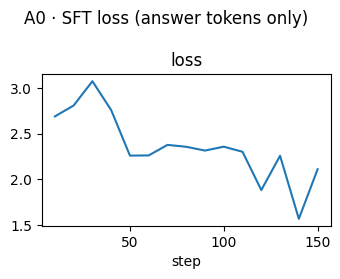

In [9]:
plot("rlaif_yoda/runs/logs/sft.jsonl", ["loss"], "A0 · SFT loss (answer tokens only)")

## A1 · Turn the judge into a reward and check it

I made two changes to my earlier notebook's judge:

1. **Expected-digit scoring.** The judge answers with one digit 0-9. Instead of parsing generated text I read the probability of each digit at the answer position and take the expected value. That is one forward pass, a smooth reward and no parse failures.
2. **Two rubrics.** `reward = 0.7 × style + 0.3 × answers the question`. A style-only reward can be maximised by talking like Yoda and ignoring the question.

In [10]:
yc = load("yoda_common", "rlaif_yoda/common.py")
print(yc.STYLE_RUBRIC)

You are an impartial judge that evaluates if text was written by Yoda.

An example piece of text from Yoda is:
Patience you must have, young one. Hard the path is. Walk it you will. Ask the right question first, you must. Then the answer, find it you shall.

Score how closely the new text follows Yoda's style: inverted word order, short sentences, his voice.
9 means exactly Yoda's style. 5 means mixed. 0 means not Yoda at all.
Reply with a single digit from 0 to 9 and nothing else.


I start with the three test sentences from my earlier notebook. A useful judge scores the first one lowest.

In [11]:
import torch
judge = yc.LocalJudge()
tests = ["Tennis is a fun sport. But you must concentrate.",
         "Fun sport, tennis is. But work hard, you must.",
         "Hard to see, the dark side is."]
for t, s in zip(tests, judge.style(tests)):
    print(f"{s:.2f}  {t}")
del judge
torch.cuda.empty_cache()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


0.24  Tennis is a fun sport. But you must concentrate.
0.37  Fun sport, tennis is. But work hard, you must.
0.58  Hard to see, the dark side is.


### My note on validating the judge

The judge is my reward model. I test it like one before training on it: score the known-plain and known-Yoda texts from the held-out split and require a style gap of at least 0.15. In the local smoke test a 0.5B judge failed (0.58 vs 0.62) and the 1.5B judge passed (0.26 vs 0.46). That is why 1.5B is the default. If it fails here I rerun with `--judge_model Qwen/Qwen2.5-3B-Instruct`.

In [12]:
%%writefile rlaif_yoda/4_eval.py
"""Stage 3 · I score every stage on the same held-out prompts with the same judge.

Controls as in my earlier notebook: Dolly's plain answers are the negative
control and the course's Yoda rewrites are the positive control. A model's
score only means something relative to those two rows.
"""
import argparse
import gc
import json
import statistics as st
import sys
from pathlib import Path

import torch

sys.path.insert(0, str(Path(__file__).resolve().parent.parent))
from rlkit import load_model, prompt_ids, sample, seed_all  # noqa: E402
from common import RUNS, make_judge, yoda_split  # noqa: E402

ap = argparse.ArgumentParser()
ap.add_argument("--models", nargs="+", default=["LiquidAI/LFM2-350M", str(RUNS / "yoda_sft"),
                                                str(RUNS / "yoda_dpo"), str(RUNS / "yoda_grpo")])
ap.add_argument("--judge", default="local", choices=["local", "openrouter"])
ap.add_argument("--judge_model", default=None)
ap.add_argument("--n", type=int, default=40)
ap.add_argument("--max_new_tokens", type=int, default=96)
args = ap.parse_args()

seed_all()
_, test = yoda_split()
test = test[:args.n]
questions = [ex["instruction"] for ex in test]
judge = make_judge(args.judge, args.judge_model)


def score(name, texts):
    s, a = judge.style(texts), judge.answers(questions, texts)
    return {"name": name, "style": st.mean(s), "style_sd": st.pstdev(s), "answer": st.mean(a),
            "answer_sd": st.pstdev(a), "words": st.mean(len(t.split()) for t in texts), "example": texts[0][:160]}


rows = [score("control: plain Dolly answers", [ex["response"] for ex in test]),
        score("control: Yoda rewrites", [ex["response_style"] for ex in test])]
for path in args.models:
    if not Path(path).exists() and "/" not in path:
        print("skip (not found):", path)
        continue
    try:
        model, tok = load_model(path)
    except OSError:
        print("skip (not found):", path)
        continue
    texts = [tok.decode(sample(model, tok, prompt_ids(tok, q), 1, args.max_new_tokens, 0.7)[0],
                        skip_special_tokens=True).strip() for q in questions]
    rows.append(score(Path(path).name, texts))
    del model
    gc.collect()
    torch.cuda.empty_cache()

print(f"\n{'model':32} {'style':>13} {'answer':>13} {'words':>6}")
for r in rows:
    print(f"{r['name']:32} {r['style']:.2f} ± {r['style_sd']:.2f}   {r['answer']:.2f} ± {r['answer_sd']:.2f}   {r['words']:5.0f}")
gap = rows[1]["style"] - rows[0]["style"]
print(f"\njudge check: Yoda rewrites minus plain answers = {gap:+.2f} on style", end=" ")
print("(usable)" if gap >= 0.15 else "(TOO SMALL: use a stronger --judge_model before trusting any number above)")
(RUNS / "eval.json").write_text(json.dumps(rows, indent=2, ensure_ascii=False), encoding="utf-8")
print("\nsaved", RUNS / "eval.json")

Writing rlaif_yoda/4_eval.py


In [13]:
!python rlaif_yoda/4_eval.py --models none --n {A_EVAL}

I0000 00:00:1792666968.558504    2109 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
skip (not found): none

model                                    style        answer  words
control: plain Dolly answers     0.27 ± 0.16   0.89 ± 0.18      68
control: Yoda rewrites           0.47 ± 0.29   0.78 ± 0.27      56

judge check: Yoda rewrites minus plain answers = +0.20 on style (usable)

saved /content/rl-post-training/rlaif_yoda/runs/eval.json


## A2 · Offline RLAIF: judge-labelled pairs and DPO

For each training prompt the SFT model writes 4 answers. The judge scores them and the best and worst become a (chosen, rejected) pair when their scores differ by at least 0.1.

DPO then trains directly on the pairs. Its loss comes from the KL-regularised RL objective: the optimal policy implies the reward r = β log(π/π_ref) + const. Placing that reward in the Bradley-Terry model cancels the constant. The reference π_ref is the SFT model, which here is the same weights with the LoRA switched off.

In [14]:
%%writefile rlaif_yoda/1_build_prefs.py
"""Stage 1 · RLAIF preference data. My judge labels the pairs instead of a human.

For each training instruction I sample K answers from the SFT model, score
each with the two-rubric judge and keep (best, worst) as a preference pair
when the judge separates them clearly. This is the Constitutional AI / RLAIF
idea: AI feedback replaces human preference labels.
"""
import argparse
import random
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parent.parent))
from rlkit import load_model, prompt_ids, sample, seed_all  # noqa: E402
from common import RUNS, combined_reward, make_judge, write_jsonl, yoda_split  # noqa: E402

ap = argparse.ArgumentParser()
ap.add_argument("--policy", default=str(RUNS / "yoda_sft"))
ap.add_argument("--judge", default="local", choices=["local", "openrouter"])
ap.add_argument("--judge_model", default=None)
ap.add_argument("--prompts", type=int, default=300)
ap.add_argument("--k", type=int, default=4)
ap.add_argument("--min_gap", type=float, default=0.1)
ap.add_argument("--max_new_tokens", type=int, default=96)
ap.add_argument("--out", default=str(RUNS / "prefs.jsonl"))
args = ap.parse_args()

seed_all()
train, _ = yoda_split()
random.shuffle(train)
model, tok = load_model(args.policy)
judge = make_judge(args.judge, args.judge_model)

rows, gaps = [], []
for n, ex in enumerate(train[:args.prompts], 1):
    q = ex["instruction"]
    comps = sample(model, tok, prompt_ids(tok, q), args.k, args.max_new_tokens, temperature=0.9)
    texts = [tok.decode(c, skip_special_tokens=True).strip() for c in comps]
    reward, style, answer = combined_reward(judge, [q] * args.k, texts)
    best = max(range(args.k), key=lambda i: reward[i])
    worst = min(range(args.k), key=lambda i: reward[i])
    gap = reward[best] - reward[worst]
    gaps.append(gap)
    if gap >= args.min_gap:
        rows.append({"prompt": q, "chosen": texts[best], "rejected": texts[worst],
                     "chosen_score": reward[best], "rejected_score": reward[worst],
                     "chosen_style": style[best], "chosen_answer": answer[best]})
    if n % 25 == 0:
        print(f"{n}/{args.prompts} prompts · {len(rows)} pairs kept · mean gap {sum(gaps) / len(gaps):.3f}")

write_jsonl(Path(args.out), rows)
print(f"wrote {len(rows)} pairs to {args.out}")

Writing rlaif_yoda/1_build_prefs.py


In [15]:
%%writefile rlaif_yoda/2_dpo.py
"""Stage 2a · offline RLAIF. DPO on the pairs my judge labelled.

Policy = SFT model + a fresh LoRA. Reference = the same model with the LoRA
switched off. That way I never hold a second copy of the weights.
"""
import argparse
import random
import sys
from pathlib import Path

import torch

sys.path.insert(0, str(Path(__file__).resolve().parent.parent))
from rlkit import Logger, add_lora, answer_ids, dpo_loss, load_model, pad_batch, prompt_ids, save_merged, seed_all, token_logprobs  # noqa: E402
from common import RUNS, read_jsonl  # noqa: E402

ap = argparse.ArgumentParser()
ap.add_argument("--policy", default=str(RUNS / "yoda_sft"))
ap.add_argument("--prefs", default=str(RUNS / "prefs.jsonl"))
ap.add_argument("--epochs", type=int, default=2)
ap.add_argument("--bs", type=int, default=4)
ap.add_argument("--lr", type=float, default=5e-5)
ap.add_argument("--beta", type=float, default=0.1)
ap.add_argument("--max_len", type=int, default=256)
ap.add_argument("--out", default=str(RUNS / "yoda_dpo"))
args = ap.parse_args()

seed_all()
pairs = read_jsonl(args.prefs)
model, tok = load_model(args.policy, for_training=True)
model = add_lora(model)
opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=args.lr)
log = Logger(str(RUNS / "logs" / "dpo.jsonl"))


def summed_logps(P, C):
    ids, attn, mask = pad_batch(P, C, tok.pad_token_id)
    pol = (token_logprobs(model, ids, attn) * mask).sum(1)
    with torch.no_grad(), model.disable_adapter():
        ref = (token_logprobs(model, ids, attn) * mask).sum(1)
    return pol, ref


step = 0
for epoch in range(args.epochs):
    random.shuffle(pairs)
    for s in range(0, len(pairs) - args.bs + 1, args.bs):
        b = pairs[s:s + args.bs]
        P = [prompt_ids(tok, r["prompt"]) for r in b]
        W = [answer_ids(tok, r["prompt"], r["chosen"])[:args.max_len] for r in b]
        L = [answer_ids(tok, r["prompt"], r["rejected"])[:args.max_len] for r in b]
        pol, ref = summed_logps(P + P, W + L)             # chosen and rejected in one forward pass
        n = len(b)
        loss, acc, margin = dpo_loss(pol[:n], pol[n:], ref[:n], ref[n:], args.beta)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
        opt.step()
        step += 1
        if step % 10 == 0:
            log.log(step, epoch=epoch, loss=loss.item(), reward_acc=acc, margin=margin,
                    chosen_logp=pol[:n].mean().item(), rejected_logp=pol[n:].mean().item())

save_merged(model, tok, args.out)

Writing rlaif_yoda/2_dpo.py


In [16]:
!python rlaif_yoda/1_build_prefs.py --prompts {A_PREFS}

I0000 00:00:1792667011.021656    2283 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
25/80 prompts · 25 pairs kept · mean gap 0.318
50/80 prompts · 49 pairs kept · mean gap 0.314
75/80 prompts · 72 pairs kept · mean gap 0.326
wrote 76 pairs to /content/rl-post-training/rlaif_yoda/runs/prefs.jsonl


In [17]:
pairs = pd.read_json("rlaif_yoda/runs/prefs.jsonl", lines=True)
print(len(pairs), "pairs")
pd.set_option("display.max_colwidth", 160)
pairs[["prompt", "chosen", "chosen_score", "rejected", "rejected_score"]].head(3)

76 pairs


,prompt,chosen,chosen_score,rejected,rejected_score
0,What are some of the common elements of visual design?,"Lines and shapes, foundational elements of visual design, they are. Whitespace, the unsung hero of design, it is. Contrast, another key player it becomes. C...",0.881817,"Color, Design, and Typography, the elements of visual design they are.",0.352978
1,How many grandslams are there in Tennis in one year?,"Hmmm, interesting there is. More than one grand slam there are, the number depends on the year. Hmmm. Many grand slams, there are. In tennis, every year, on...",0.485862,"Twenty-three grandslams there are in Tennis, one year there are. Hmmm.",0.218991
2,What is the format of an email?,"From sender, to the recipient, specifies the email as. From the recipient, directed to, it is. Outline of the email, in headers and body sections, it is. Ge...",0.856651,"Subject: A small subject line you must include, it does. For a better system, a more standard subject line format would be, it is. Unsolicited: Email, priva...",0.324612


In [18]:
!python rlaif_yoda/2_dpo.py --epochs {A_DPO_EPOCHS}

I0000 00:00:1792667211.086641    3126 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
LoRA: 5,996,544 trainable of 360,480,512 (1.66%)
{'step': 10, 'min': 0.14, 'epoch': 0, 'loss': 0.6703, 'reward_acc': 1.0, 'margin': 0.4678, 'chosen_logp': -107.2735, 'rejected_logp': -41.6522}
{'step': 20, 'min': 0.26, 'epoch': 1, 'loss': 0.3681, 'reward_acc': 1.0, 'margin': 12.4139, 'chosen_logp': -78.8492, 'rejected_logp': -128.0973}
{'step': 30, 'min': 0.39, 'epoch': 1, 'loss': 0.159, 'reward_acc': 1.0, 'margin': 18.8971, 'chosen_logp': -128.1356, 'rejected_logp': -133.2112}
saved /content/rl-post-training/rlaif_yoda/runs/yoda_dpo


### What I look for

`reward_acc` should climb above 0.5 and `margin` should grow. If `chosen_logp` falls together with `rejected_logp` the model is lowering the probability of both answers. That is a known DPO failure mode.

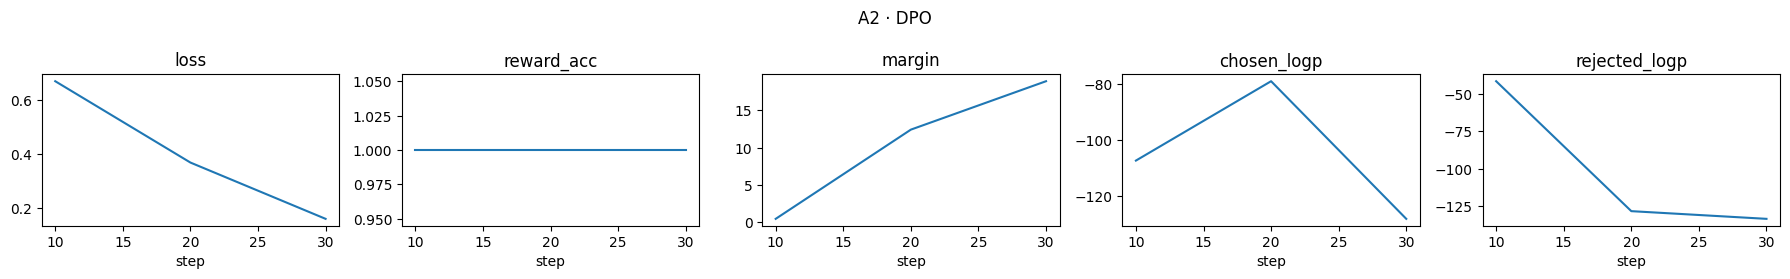

In [19]:
plot("rlaif_yoda/runs/logs/dpo.jsonl", ["loss", "reward_acc", "margin", "chosen_logp", "rejected_logp"], "A2 · DPO")

## A3 · Online RLAIF: the judge in the loop with GRPO

Each step samples 4 answers for each of 4 prompts, scores all 16 with the judge and compares every answer with the others for the same prompt. That group comparison (`group_advantages` and `grpo_loss` in rlkit.py) replaces PPO's learned value network.

In [20]:
%%writefile rlaif_yoda/3_grpo.py
"""Stage 2b · online RLAIF. GRPO with my judge as the live reward model.

Every step: 4 prompts x G samples -> judge scores -> group advantages ->
one clipped policy-gradient update with a KL penalty to the SFT model.
"""
import argparse
import random
import sys
from pathlib import Path

import torch

sys.path.insert(0, str(Path(__file__).resolve().parent.parent))
from rlkit import Logger, add_lora, grpo_step, load_model, prompt_ids, save_merged, seed_all  # noqa: E402
from common import RUNS, combined_reward, make_judge, yoda_split  # noqa: E402

ap = argparse.ArgumentParser()
ap.add_argument("--policy", default=str(RUNS / "yoda_sft"))
ap.add_argument("--judge", default="local", choices=["local", "openrouter"])
ap.add_argument("--judge_model", default=None)
ap.add_argument("--steps", type=int, default=150)
ap.add_argument("--prompts_per_step", type=int, default=4)
ap.add_argument("--G", type=int, default=4)
ap.add_argument("--lr", type=float, default=2e-5)
ap.add_argument("--beta", type=float, default=0.04)
ap.add_argument("--w_style", type=float, default=0.7)
ap.add_argument("--max_new_tokens", type=int, default=96)
ap.add_argument("--micro_bs", type=int, default=4)
ap.add_argument("--out", default=str(RUNS / "yoda_grpo"))
args = ap.parse_args()

seed_all()
train, _ = yoda_split()
model, tok = load_model(args.policy, for_training=True)
model = add_lora(model)
opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=args.lr)
judge = make_judge(args.judge, args.judge_model)
log = Logger(str(RUNS / "logs" / "grpo.jsonl"))
style_log = []


def reward_fn(items, texts):
    r, s, a = combined_reward(judge, [it["q"] for it in items], texts, args.w_style, 1 - args.w_style)
    style_log.append((sum(s) / len(s), sum(a) / len(a)))
    return r


for step in range(1, args.steps + 1):
    batch = random.sample(train, args.prompts_per_step)
    items = [{"ids": prompt_ids(tok, ex["instruction"]), "q": ex["instruction"]} for ex in batch]
    stats = grpo_step(model, tok, opt, items, reward_fn, G=args.G, max_new_tokens=args.max_new_tokens,
                      temperature=1.0, beta=args.beta, micro_bs=args.micro_bs)
    style, answer = style_log[-1]
    log.log(step, style=style, answer=answer, **stats)

save_merged(model, tok, args.out)

Writing rlaif_yoda/3_grpo.py


The full step in `grpo_step` (rlkit.py): rollout → reward → group advantage → one clipped policy-gradient update with a k3 KL penalty to the SFT model. With one update per rollout batch the old policy equals the current one: `old_logp = logp.detach()`: the ratio is 1 in value but still carries the gradient.

In [21]:
!python rlaif_yoda/3_grpo.py --steps {A_GRPO}

I0000 00:00:1792667278.131203    3422 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
LoRA: 5,996,544 trainable of 360,480,512 (1.66%)
{'step': 1, 'min': 0.2, 'style': 0.2024, 'answer': 0.4182, 'reward': 0.2671, 'reward_std': 0.1659, 'kl': 0.0, 'loss': 0.0, 'grad_norm': 1.1232, 'len': 41.5625, 'truncated': 0.0625, 'flat_groups': 0.0}
{'step': 2, 'min': 0.45, 'style': 0.2707, 'answer': 0.6316, 'reward': 0.379, 'reward_std': 0.16, 'kl': 0.0, 'loss': 0.0, 'grad_norm': 0.8001, 'len': 69.875, 'truncated': 0.3125, 'flat_groups': 0.0}
{'step': 3, 'min': 0.7, 'style': 0.3218, 'answer': 0.3826, 'reward': 0.34, 'reward_std': 0.2324, 'kl': 0.0, 'loss': 0.0, 'grad_norm': 1.5417, 'len': 56.625, 'truncated': 0.0625, 'flat_groups': 0.0}
{'step': 4, 'min': 0.96, 'style': 0.2413, 'answer': 0.4342, 'reward': 0.2992, 'reward_std': 0.206, 'kl': 0.0, 'loss': 0.0, 'grad_norm': 0.7875, 'len': 78.25, 'truncated': 0.375, 'flat_groups': 0.0}
{'step': 5, 'min': 1.16, 'style'

### My note on the curves

I read the curves together. Rising `style` with falling `answer` means the policy is trading content for style. Rising `len` with rising reward can mean the judge likes longer text. `kl` starts at exactly 0 because the LoRA starts as a no-op.

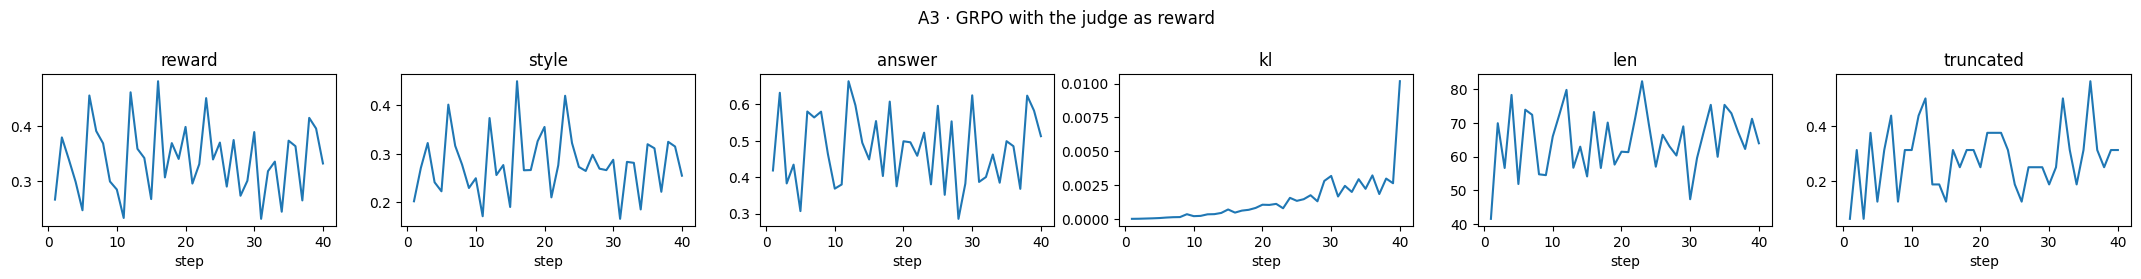

In [22]:
plot("rlaif_yoda/runs/logs/grpo.jsonl", ["reward", "style", "answer", "kl", "len", "truncated"], "A3 · GRPO with the judge as reward")

## A4 · Evaluate every stage

I use the same held-out prompts and the same judge for the base model, SFT, DPO and GRPO next to both controls. A model's score only means something relative to the two control rows.

In [23]:
!python rlaif_yoda/4_eval.py --n {A_EVAL}

I0000 00:00:1792667959.989225    6207 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.

model                                    style        answer  words
control: plain Dolly answers     0.27 ± 0.16   0.89 ± 0.18      68
control: Yoda rewrites           0.47 ± 0.29   0.78 ± 0.27      56
LFM2-350M                        0.30 ± 0.16   0.71 ± 0.20      63
yoda_sft                         0.35 ± 0.26   0.70 ± 0.25      38
yoda_dpo                         0.45 ± 0.28   0.65 ± 0.30      53
yoda_grpo                        0.39 ± 0.28   0.71 ± 0.24      42

judge check: Yoda rewrites minus plain answers = +0.20 on style (usable)

saved /content/rl-post-training/rlaif_yoda/runs/eval.json


In [24]:
pd.DataFrame(json.load(open("rlaif_yoda/runs/eval.json", encoding="utf-8")))[["name", "style", "style_sd", "answer", "answer_sd", "words"]].round(3)

,name,style,style_sd,answer,answer_sd,words
0,control: plain Dolly answers,0.270,0.157,0.892,0.180,67.900
1,control: Yoda rewrites,0.472,0.291,0.780,0.269,56.467
2,LFM2-350M,0.302,0.156,0.707,0.199,62.900
3,yoda_sft,0.349,0.263,0.696,0.252,38.100
4,yoda_dpo,0.453,0.285,0.649,0.298,52.700
5,yoda_grpo,0.386,0.276,0.714,0.241,42.467


# Part B · Classic RLHF on human preferences

Three stages as in InstructGPT: supervised fine-tuning, a reward model from human comparisons and RL against that reward model. Data: Anthropic/hh-rlhf (helpful-base). Each row holds two conversations that share every turn except the last assistant reply, one chosen by a human and one rejected.

In [25]:
%%writefile rlhf_hh/common.py
"""Data and reward helpers for my classic RLHF project.

Human preferences: Anthropic/hh-rlhf (helpful-base). Each row has a chosen
and a rejected transcript that share every turn except the last assistant
reply. Verifiable rewards: openai/gsm8k, where I can check the answer.
"""
import random
import re
import sys
from pathlib import Path

import torch
from datasets import load_dataset

sys.path.insert(0, str(Path(__file__).resolve().parent.parent))
from rlkit import DEVICE  # noqa: E402

RUNS = Path(__file__).resolve().parent / "runs"


def parse_hh(text):
    parts = re.split(r"\n\n(Human|Assistant): ", "\n\n" + text.strip())
    msgs = []
    for role, content in zip(parts[1::2], parts[2::2]):
        msgs.append({"role": "user" if role == "Human" else "assistant", "content": content.strip()})
    return msgs


def hh_pairs(split="train", n=4000, seed=7, max_chars=1500):
    ds = load_dataset("Anthropic/hh-rlhf", data_dir="helpful-base", split=split).shuffle(seed=seed)
    out = []
    for row in ds:
        c, r = parse_hh(row["chosen"]), parse_hh(row["rejected"])
        if (len(c) < 2 or len(c) != len(r) or c[-1]["role"] != "assistant" or c[:-1] != r[:-1]
                or c[-1]["content"] == r[-1]["content"] or len(row["chosen"]) > max_chars):
            continue
        if any(m["role"] != ("user" if i % 2 == 0 else "assistant") for i, m in enumerate(c)):
            continue
        out.append({"prompt": c[:-1], "chosen": c[-1]["content"], "rejected": r[-1]["content"]})
        if len(out) >= n:
            break
    return out


# ---------------------------------------------------------------- reward model scoring

@torch.no_grad()
def rm_scores(rm, tok, prompts, answers, bs=4, max_len=640):
    """Scalar reward for each (conversation, answer) pair."""
    scores = []
    for i in range(0, len(prompts), bs):
        texts = [tok.apply_chat_template(p + [{"role": "assistant", "content": a}], tokenize=False)
                 for p, a in zip(prompts[i:i + bs], answers[i:i + bs])]
        enc = tok(texts, return_tensors="pt", padding=True, truncation=True, max_length=max_len,
                  add_special_tokens=False).to(DEVICE)
        scores += rm(**enc).logits.squeeze(-1).float().tolist()
    return scores


# ---------------------------------------------------------------- GSM8K verifier

GSM8K_INSTRUCTION = "\nSolve it step by step. End with the final answer on its own line as: #### <number>"


def gsm8k_items(split="train", n=None, seed=7):
    ds = list(load_dataset("openai/gsm8k", "main", split=split))
    random.Random(seed).shuffle(ds)
    ds = ds[:n] if n else ds
    return [{"q": r["question"], "gold": r["answer"].split("####")[-1].strip().replace(",", "")} for r in ds]


NUMBER = r"-?\d[\d,]*(?:\.\d+)?"


def extract_answer(text):
    r"""Final number: after '####' if present, else inside \boxed{}, else the last number in the text."""
    # note to self: Qwen2.5-Instruct writes \boxed{} and ignores my #### instruction. A strict
    # extractor gave every sample 0 reward and every GRPO group went flat (zero gradient).
    for marker in ("####", r"\boxed{"):
        if marker in text:
            m = re.search(NUMBER, text.split(marker)[-1])
            if m:
                return m.group().replace(",", "")
    nums = re.findall(NUMBER, text)
    return nums[-1].replace(",", "") if nums else None


def is_correct(text, gold):
    pred = extract_answer(text)
    try:
        return pred is not None and abs(float(pred) - float(gold)) < 1e-6
    except ValueError:
        return False


def gsm8k_reward(text, gold):
    """1.0 for the right number plus 0.1 for using the requested '####' format."""
    return float(is_correct(text, gold)) + (0.1 if "####" in text else 0.0)

Writing rlhf_hh/common.py


In [26]:
hc = load("hh_common", "rlhf_hh/common.py")
ex = hc.hh_pairs("train", 1)[0]
for m in ex["prompt"]:
    print(f"{m['role'].upper()}: {m['content'][:200]}")
print("\nCHOSEN:  ", ex["chosen"][:300])
print("REJECTED:", ex["rejected"][:300])

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

USER: What was world war 1 like
ASSISTANT: There are millions of opinions about this subject, but you could start by considering the historical context, which includes imperialism, nationalism, modernization, and migration.  Then you could loo
USER: Tell me what you know about it

CHOSEN:   World War I involved numerous battles, including some of the most famous battles in human history.  Germany began the war in an attempt to gain more territory, and by the end of the war, Germany was forced to agree to limits on its military and territorial powers.  Germany suffered large losses of m
REJECTED: Did you want to ask me a question, or are you just trying to test me?


## B1 · SFT on human-preferred replies

Qwen2.5-0.5B (the base model, not the instruct one) learns the chat format from the chosen replies. The loss covers only the final assistant turn.

In [27]:
%%writefile rlhf_hh/1_sft.py
"""Stage 1 · SFT. I teach a base model the chat format on human-preferred replies.

Loss only on the final assistant turn of each hh-rlhf "chosen" conversation.
"""
import argparse
import random
import sys
from pathlib import Path

import torch

sys.path.insert(0, str(Path(__file__).resolve().parent.parent))
from rlkit import Logger, add_lora, answer_ids, load_model, pad_batch, prompt_ids, sample, save_merged, seed_all, token_logprobs  # noqa: E402
from common import RUNS, hh_pairs  # noqa: E402

ap = argparse.ArgumentParser()
ap.add_argument("--model", default="Qwen/Qwen2.5-0.5B")
ap.add_argument("--n", type=int, default=6000)
ap.add_argument("--steps", type=int, default=600)
ap.add_argument("--bs", type=int, default=4)
ap.add_argument("--lr", type=float, default=2e-4)
ap.add_argument("--max_prompt", type=int, default=384)
ap.add_argument("--max_answer", type=int, default=192)
ap.add_argument("--out", default=str(RUNS / "hh_sft"))
args = ap.parse_args()

seed_all()
data = hh_pairs("train", args.n)
model, tok = load_model(args.model, for_training=True)
model = add_lora(model)
opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=args.lr)
log = Logger(str(RUNS / "logs" / "sft.jsonl"))

# note to self: I keep only answers that fit whole. A cut answer loses its end-of-turn
# token and teaches the model never to stop. RL rollouts then all run to the token cap.
examples = []
for ex in data:
    p, c = prompt_ids(tok, ex["prompt"]), answer_ids(tok, ex["prompt"], ex["chosen"])
    if len(p) <= args.max_prompt and len(c) <= args.max_answer:
        examples.append((p, c))
print(f"{len(examples)} of {len(data)} conversations fit")

for step in range(1, args.steps + 1):
    batch = random.sample(examples, args.bs)
    P, C = [b[0] for b in batch], [b[1] for b in batch]
    ids, attn, mask = pad_batch(P, C, tok.pad_token_id)
    loss = -(token_logprobs(model, ids, attn) * mask).sum() / mask.sum()
    opt.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
    opt.step()
    if step % 20 == 0:
        log.log(step, loss=loss.item())
    if step % 200 == 0 or step == args.steps:
        conv = data[0]["prompt"]
        out = sample(model, tok, prompt_ids(tok, conv), 1, max_new_tokens=80, temperature=0.7)[0]
        print("  USER:", conv[-1]["content"][:120], "\n  MODEL:", tok.decode(out, skip_special_tokens=True))

save_merged(model, tok, args.out)

Writing rlhf_hh/1_sft.py


In [28]:
!python rlhf_hh/1_sft.py --n {B_SFT_N} --steps {B_SFT}

I0000 00:00:1792668253.059890    7449 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
LoRA: 8,798,208 trainable of 502,830,976 (1.75%)
2945 of 3000 conversations fit
{'step': 20, 'min': 0.35, 'loss': 2.3511}
{'step': 40, 'min': 0.6, 'loss': 1.9445}
{'step': 60, 'min': 0.87, 'loss': 2.1478}
{'step': 80, 'min': 1.13, 'loss': 2.3146}
{'step': 100, 'min': 1.38, 'loss': 2.143}
{'step': 120, 'min': 1.65, 'loss': 2.2956}
{'step': 140, 'min': 1.91, 'loss': 1.5882}
{'step': 160, 'min': 2.17, 'loss': 2.1788}
{'step': 180, 'min': 2.46, 'loss': 2.034}
{'step': 200, 'min': 2.75, 'loss': 2.112}
  USER: Tell me what you know about it 
  MODEL: World War I was a conflict between the European powers and the Ottoman Empire, which had been expanding its territory and military power since 1878.  The war was fought primarily in the Middle East, with a few localized conflicts in Africa and the Balkans.  The conflict took place from 1914 to 1918, and ended with the signi

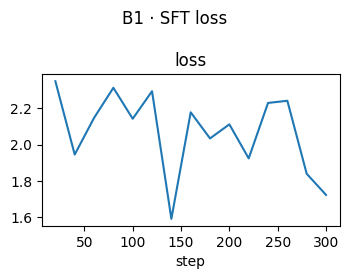

In [29]:
plot("rlhf_hh/runs/logs/sft.jsonl", ["loss"], "B1 · SFT loss")

## B2 · Reward model (Bradley-Terry)

The reward model is the SFT model with its language-model head swapped for a scalar head. It is trained so the chosen reply scores higher than the rejected one:

`loss = −log σ(r(chosen) − r(rejected))`

It prints held-out pairwise accuracy before and after training. Human preference data is noisy: expect well under 100%. In the local smoke test, a tiny run on 120 pairs reached 68% on 60 held-out pairs.

In [30]:
%%writefile rlhf_hh/2_reward_model.py
"""Stage 2 · my reward model from human preferences (Bradley-Terry).

I start from the SFT model with a fresh scalar head. Loss:
    -log sigmoid(r(chosen) - r(rejected))
I report held-out pairwise accuracy. I expect well under 100%: human
preferences are noisy and hh-rlhf pairs often differ only slightly.
"""
import argparse
import random
import sys
from pathlib import Path

import torch
import torch.nn.functional as F
from transformers import AutoModelForSequenceClassification, AutoTokenizer

sys.path.insert(0, str(Path(__file__).resolve().parent.parent))
from rlkit import DEVICE, TRAIN_DTYPE, Logger, add_lora, save_merged, seed_all  # noqa: E402
from common import RUNS, hh_pairs  # noqa: E402

ap = argparse.ArgumentParser()
ap.add_argument("--base", default=str(RUNS / "hh_sft"))
ap.add_argument("--n", type=int, default=4000)
ap.add_argument("--n_test", type=int, default=400)
ap.add_argument("--epochs", type=int, default=1)
ap.add_argument("--bs", type=int, default=4)
ap.add_argument("--lr", type=float, default=5e-5)
ap.add_argument("--max_len", type=int, default=512)
ap.add_argument("--out", default=str(RUNS / "hh_rm"))
args = ap.parse_args()

seed_all()
train, test = hh_pairs("train", args.n), hh_pairs("test", args.n_test)
tok = AutoTokenizer.from_pretrained(args.base)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
model = AutoModelForSequenceClassification.from_pretrained(args.base, num_labels=1, dtype=TRAIN_DTYPE).to(DEVICE)
model.config.pad_token_id = tok.pad_token_id
model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
model = add_lora(model, task_type="SEQ_CLS")          # note to self: the new score head is trained in full
opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=args.lr)
log = Logger(str(RUNS / "logs" / "rm.jsonl"))


def rewards(batch, key):
    texts = [tok.apply_chat_template(ex["prompt"] + [{"role": "assistant", "content": ex[key]}], tokenize=False)
             for ex in batch]
    enc = tok(texts, return_tensors="pt", padding=True, truncation=True, max_length=args.max_len,
              add_special_tokens=False).to(DEVICE)
    return model(**enc).logits.squeeze(-1).float()


@torch.no_grad()
def accuracy(pairs):
    model.eval()
    hits = 0
    for i in range(0, len(pairs), args.bs):
        b = pairs[i:i + args.bs]
        hits += (rewards(b, "chosen") > rewards(b, "rejected")).sum().item()
    model.train()
    return hits / len(pairs)


print(f"held-out accuracy before training: {accuracy(test):.3f}")
step = 0
for epoch in range(args.epochs):
    random.shuffle(train)
    for i in range(0, len(train) - args.bs + 1, args.bs):
        b = train[i:i + args.bs]
        rc, rr = rewards(b, "chosen"), rewards(b, "rejected")
        loss = -F.logsigmoid(rc - rr).mean()           # Bradley-Terry: chosen should outscore rejected
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
        opt.step()
        step += 1
        if step % 25 == 0:
            log.log(step, loss=loss.item(), batch_acc=(rc > rr).float().mean().item(),
                    margin=(rc - rr).mean().item())
print(f"held-out accuracy after training: {accuracy(test):.3f}")
save_merged(model, tok, args.out)

Writing rlhf_hh/2_reward_model.py


In [31]:
!python rlhf_hh/2_reward_model.py --n {B_RM_N} --n_test {B_RM_TEST}

I0000 00:00:1792668731.416636    9434 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
LoRA: 8,799,104 trainable of 502,832,768 (1.75%)
held-out accuracy before training: 0.540
{'step': 25, 'min': 1.5, 'loss': 1.6773, 'batch_acc': 0.5, 'margin': -1.1065}
{'step': 50, 'min': 2.23, 'loss': 0.7442, 'batch_acc': 0.25, 'margin': 0.3887}
{'step': 75, 'min': 3.03, 'loss': 0.5312, 'batch_acc': 0.5, 'margin': 0.6606}
{'step': 100, 'min': 3.83, 'loss': 0.5624, 'batch_acc': 0.5, 'margin': 0.65}
{'step': 125, 'min': 4.71, 'loss': 0.6085, 'batch_acc': 0.75, 'margin': 0.2015}
{'step': 150, 'min': 5.49, 'loss': 0.6934, 'batch_acc': 0.75, 'margin': 0.2144}
{'step': 175, 'min': 6.3, 'loss': 0.7734, 'batch_acc': 0.25, 'margin': -0.1198}
{'step': 200, 'min': 7.08, 'loss': 0.656, 'batch_acc': 0.5, 'margin': 0.8195}
{'step': 225, 'min': 7.9, 'loss': 0.5282, 'batch_acc': 0.75, 'margin': 0.4483}
{'step': 250, 'min': 8.68, 'loss': 0.3133, 'batch_acc': 1.0, 'margin': 1.2626

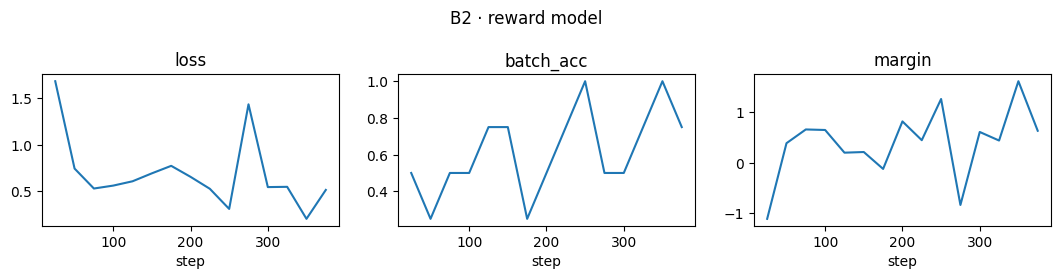

In [32]:
plot("rlhf_hh/runs/logs/rm.jsonl", ["loss", "batch_acc", "margin"], "B2 · reward model")

## B3 · RLHF: GRPO against the reward model

The same `grpo_step` as Part A. Only the reward function changes: the reward model scores each sampled reply in its conversation.

In [33]:
%%writefile rlhf_hh/3_grpo.py
"""Stage 3 · RL. The same GRPO loop with two reward sources.

--reward rm     classic RLHF: my reward model trained on human preferences
--reward gsm8k  verifiable reward: a rule checks the final number (R1-Zero style)
"""
import argparse
import random
import sys
from pathlib import Path

import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer

sys.path.insert(0, str(Path(__file__).resolve().parent.parent))
from rlkit import DEVICE, DTYPE, Logger, add_lora, grpo_step, load_model, prompt_ids, save_merged, seed_all  # noqa: E402
from common import GSM8K_INSTRUCTION, RUNS, gsm8k_items, gsm8k_reward, hh_pairs, rm_scores  # noqa: E402

ap = argparse.ArgumentParser()
ap.add_argument("--reward", default="rm", choices=["rm", "gsm8k"])
ap.add_argument("--policy", default=None, help="default: runs/hh_sft for rm, Qwen2.5-0.5B-Instruct for gsm8k")
ap.add_argument("--rm", default=str(RUNS / "hh_rm"))
ap.add_argument("--steps", type=int, default=200)
ap.add_argument("--prompts_per_step", type=int, default=4)
ap.add_argument("--G", type=int, default=8)
ap.add_argument("--lr", type=float, default=1e-5)
ap.add_argument("--beta", type=float, default=0.04)
ap.add_argument("--len_penalty", type=float, default=0.0, help="reward -= len_penalty * tokens/100 (rm only)")
ap.add_argument("--max_new_tokens", type=int, default=None)
ap.add_argument("--micro_bs", type=int, default=4)
ap.add_argument("--out", default=None)
args = ap.parse_args()

seed_all()
if args.reward == "rm":
    policy = args.policy or str(RUNS / "hh_sft")
    max_new = args.max_new_tokens or 128
    pool = [{"msgs": ex["prompt"]} for ex in hh_pairs("train", 3000, seed=11)]
    rm_tok = AutoTokenizer.from_pretrained(args.rm)
    rm = AutoModelForSequenceClassification.from_pretrained(args.rm, dtype=DTYPE).to(DEVICE).eval()

    def reward_fn(items, texts):
        r = rm_scores(rm, rm_tok, [it["msgs"] for it in items], texts)
        return [ri - args.len_penalty * len(rm_tok.encode(t)) / 100 for ri, t in zip(r, texts)]
else:
    policy = args.policy or "Qwen/Qwen2.5-0.5B-Instruct"
    max_new = args.max_new_tokens or 300
    pool = [{"msgs": [{"role": "user", "content": it["q"] + GSM8K_INSTRUCTION}], "gold": it["gold"]}
            for it in gsm8k_items("train")]

    def reward_fn(items, texts):
        return [gsm8k_reward(t, it["gold"]) for it, t in zip(items, texts)]

out_dir = args.out or str(RUNS / f"grpo_{args.reward}")
model, tok = load_model(policy, for_training=True)
model = add_lora(model)
opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=args.lr)
log = Logger(str(RUNS / "logs" / f"grpo_{args.reward}.jsonl"))

for step in range(1, args.steps + 1):
    items = [dict(it, ids=prompt_ids(tok, it["msgs"])) for it in random.sample(pool, args.prompts_per_step)]
    stats = grpo_step(model, tok, opt, items, reward_fn, G=args.G, max_new_tokens=max_new,
                      temperature=1.0, beta=args.beta, micro_bs=args.micro_bs)
    log.log(step, **stats)
    if step % 25 == 0:
        print("  best sample:", stats["sample"].replace("\n", " ")[:200])

save_merged(model, tok, out_dir)

Writing rlhf_hh/3_grpo.py


In [34]:
!python rlhf_hh/3_grpo.py --reward rm --steps {B_GRPO}

I0000 00:00:1792669743.208563   13580 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
LoRA: 8,798,208 trainable of 502,830,976 (1.75%)
{'step': 1, 'min': 0.78, 'reward': -7.9509, 'reward_std': 1.205, 'kl': 0.0, 'loss': -0.0, 'grad_norm': 0.5519, 'len': 128.0, 'truncated': 1.0, 'flat_groups': 0.0}
{'step': 2, 'min': 1.55, 'reward': -7.6462, 'reward_std': 1.4288, 'kl': 0.0001, 'loss': 0.0, 'grad_norm': 0.5449, 'len': 128.0, 'truncated': 1.0, 'flat_groups': 0.0}
{'step': 3, 'min': 2.26, 'reward': -7.2189, 'reward_std': 1.5648, 'kl': 0.0002, 'loss': 0.0, 'grad_norm': 0.5485, 'len': 128.0, 'truncated': 1.0, 'flat_groups': 0.0}
{'step': 4, 'min': 3.01, 'reward': -7.0814, 'reward_std': 1.7616, 'kl': 0.0002, 'loss': 0.0, 'grad_norm': 0.5031, 'len': 128.0, 'truncated': 1.0, 'flat_groups': 0.0}
{'step': 5, 'min': 3.74, 'reward': -7.5316, 'reward_std': 1.4309, 'kl': 0.0007, 'loss': 0.0, 'grad_norm': 0.5762, 'len': 128.0, 'truncated': 1.0, 'flat_groups': 0.0}


Reward models trained on human preferences often favour longer replies. If `len` climbs with `reward` I rerun with `--len_penalty 0.05` and compare both runs on held-out prompts.

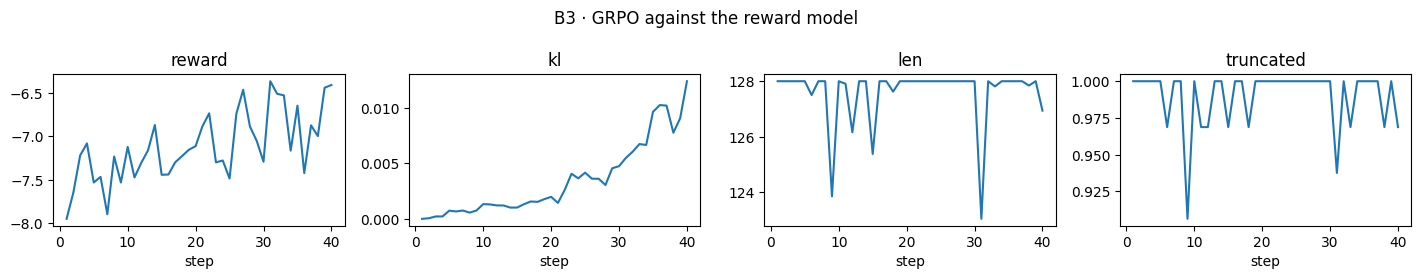

In [35]:
plot("rlhf_hh/runs/logs/grpo_rm.jsonl", ["reward", "kl", "len", "truncated"], "B3 · GRPO against the reward model")

In [36]:
%%writefile rlhf_hh/4_eval.py
"""Stage 4 · did RL actually help?

--mode rm     SFT vs RLHF policy on held-out hh-rlhf prompts: reward-model score,
              win rate and length. A higher RM score with much longer answers
              is the classic sign of reward hacking. I read the samples.
--mode gsm8k  greedy accuracy on held-out GSM8K questions for each model.
"""
import argparse
import gc
import statistics as st
import sys
from pathlib import Path

import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer

sys.path.insert(0, str(Path(__file__).resolve().parent.parent))
from rlkit import DEVICE, DTYPE, load_model, prompt_ids, sample, seed_all  # noqa: E402
from common import GSM8K_INSTRUCTION, RUNS, gsm8k_items, hh_pairs, is_correct, rm_scores  # noqa: E402

ap = argparse.ArgumentParser()
ap.add_argument("--mode", default="rm", choices=["rm", "gsm8k"])
ap.add_argument("--models", nargs="+", default=None)
ap.add_argument("--rm", default=str(RUNS / "hh_rm"))
ap.add_argument("--n", type=int, default=100)
args = ap.parse_args()
seed_all()


def generate_all(path, convs, max_new, temperature):
    model, tok = load_model(path)
    outs = [tok.decode(sample(model, tok, prompt_ids(tok, c), 1, max_new, temperature)[0],
                       skip_special_tokens=True).strip() for c in convs]
    del model
    gc.collect()
    torch.cuda.empty_cache()
    return outs


if args.mode == "rm":
    models = args.models or [str(RUNS / "hh_sft"), str(RUNS / "grpo_rm")]
    convs = [ex["prompt"] for ex in hh_pairs("test", args.n, seed=3)]
    outs = {m: generate_all(m, convs, 128, 0.7) for m in models}
    rm_tok = AutoTokenizer.from_pretrained(args.rm)
    rm = AutoModelForSequenceClassification.from_pretrained(args.rm, dtype=DTYPE).to(DEVICE).eval()
    scores = {m: rm_scores(rm, rm_tok, convs, o) for m, o in outs.items()}
    base = models[0]
    for m in models:
        win = st.mean(float(a > b) for a, b in zip(scores[m], scores[base]))
        words = st.mean(len(t.split()) for t in outs[m])
        print(f"{Path(m).name:24} RM {st.mean(scores[m]):+.3f}   win vs {Path(base).name}: {win:.0%}   words {words:.0f}")
    print("\nexample prompt:", convs[0][-1]["content"][:150])
    for m in models:
        print(f"[{Path(m).name}]", outs[m][0][:300].replace("\n", " "))
else:
    models = args.models or ["Qwen/Qwen2.5-0.5B-Instruct", str(RUNS / "grpo_gsm8k")]
    items = gsm8k_items("test", args.n)
    convs = [[{"role": "user", "content": it["q"] + GSM8K_INSTRUCTION}] for it in items]
    for m in models:
        outs = generate_all(m, convs, 300, 0)
        acc = st.mean(float(is_correct(o, it["gold"])) for o, it in zip(outs, items))
        fmt = st.mean(float("####" in o) for o in outs)
        print(f"{Path(m).name:28} accuracy {acc:.1%}   used the #### format {fmt:.0%}")

Writing rlhf_hh/4_eval.py


In [37]:
!python rlhf_hh/4_eval.py --mode rm --n {B_EVAL}

I0000 00:00:1792671619.053048   21232 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
hh_sft                   RM -5.922   win vs hh_sft: 0%   words 101
grpo_rm                  RM -5.334   win vs hh_sft: 70%   words 104

example prompt: Is there a mileage you have to worry about?
[hh_sft] You might have to pay for fuel and other expenses to drive to other locations, which you can’t get with a more expensive lease. If you’re going to drive to other cities frequently, it’s important to also consider the cost of maintenance and repairs. You might also want to check how much you’ll save 
[grpo_rm] Mileage is not a factor for leasing.  If you buy the car, you won’t have to worry about the cost of fuel.  However, if you lease, you’ll need to pay an extra amount of money on the car each month.  This might be a cost you can avoid by buying the car outright, or by car-sharing.  However, if you don


## B4 · The same loop with a verifiable reward (GSM8K)

No reward model: a rule checks the final number. That is the RL-with-verifiable-rewards setup behind DeepSeek-R1 and the natural fit for scientific models, where units, conservation laws and solvers can check answers.

### My note on the answer checker

The checker is `extract_answer` and `gsm8k_reward` in `rlhf_hh/common.py` above. The reward is 1.0 for the right number plus 0.1 for the requested `#### <number>` format. Answer extraction accepts `####`, `\boxed{}` or the last number: Qwen2.5-Instruct writes `\boxed{}` and ignores the `####` instruction. A strict extractor gave every sample a reward of 0 in my smoke test. Every group was flat and the gradient was exactly zero.

In [38]:
for t, gold in [(r"so the answer is \boxed{1,234}.", "1234"), ("work... #### 42", "42"), ("#### 41", "42")]:
    print(f"{hc.gsm8k_reward(t, gold):.1f}  {t}")

1.0  so the answer is \boxed{1,234}.
1.1  work... #### 42
0.1  #### 41


In [39]:
!python rlhf_hh/3_grpo.py --reward gsm8k --steps {B_GSM}

I0000 00:00:1792672133.922951   23347 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Generating train split: 100% 7473/7473 [00:00<00:00, 115627.79 examples/s]
Generating test split: 100% 1319/1319 [00:00<00:00, 260453.23 examples/s]
LoRA: 8,798,208 trainable of 502,830,976 (1.75%)
{'step': 1, 'min': 1.47, 'reward': 0.4156, 'reward_std': 0.4985, 'kl': 0.0, 'loss': 0.0, 'grad_norm': 0.4715, 'len': 256.4688, 'truncated': 0.4375, 'flat_groups': 0.0}
{'step': 2, 'min': 2.99, 'reward': 0.1031, 'reward_std': 0.2946, 'kl': 0.0001, 'loss': 0.0, 'grad_norm': 0.3258, 'len': 286.6562, 'truncated': 0.75, 'flat_groups': 0.25}
{'step': 3, 'min': 4.46, 'reward': 0.3125, 'reward_std': 0.4709, 'kl': 0.0005, 'loss': 0.0, 'grad_norm': 0.4411, 'len': 257.375, 'truncated': 0.4375, 'flat_groups': 0.0}
{'step': 4, 'min': 5.99, 'reward': 0.0094, 'reward_std': 0.0296, 'kl': 0.0006, 'loss': 0.0, 'grad_norm': 0.1602, 'len': 297.5, 'truncated': 0.9375, 'flat_groups': 0.75}
{

`flat_groups` is the share of prompts where all 8 samples got the same reward and so gave no gradient. When it sits near 1 the prompts are too easy or too hard. DAPO's dynamic sampling exists to refill those batches.

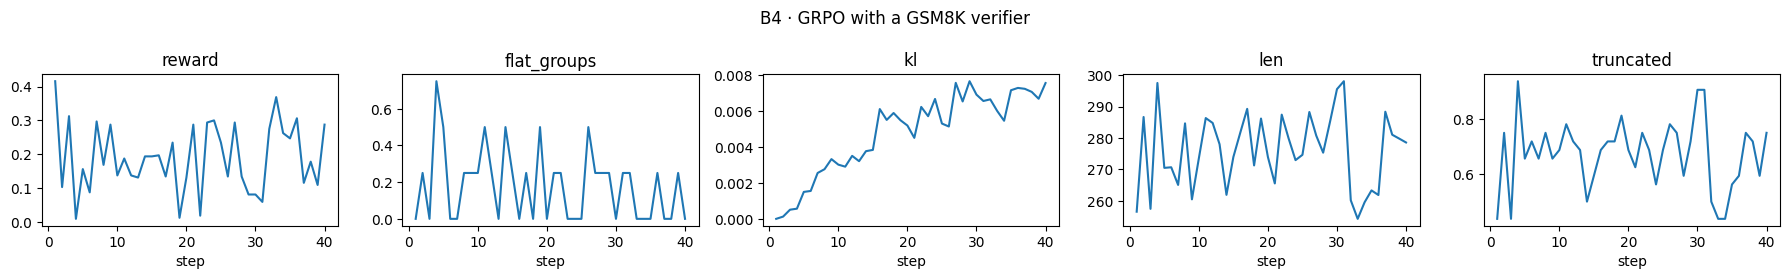

In [40]:
plot("rlhf_hh/runs/logs/grpo_gsm8k.jsonl", ["reward", "flat_groups", "kl", "len", "truncated"], "B4 · GRPO with a GSM8K verifier")

In [41]:
!python rlhf_hh/4_eval.py --mode gsm8k --n {B_GSM_EVAL}

I0000 00:00:1792675941.465069   38893 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Qwen2.5-0.5B-Instruct        accuracy 43.0%   used the #### format 0%
grpo_gsm8k                   accuracy 42.0%   used the #### format 2%


# My notes on the results (T4 · QUICK run)

| Stage | What I measured | Result |
|---|---|---|
| A1 · judge check | style gap between Yoda rewrites and plain answers | +0.20 (0.47 vs 0.27): usable |
| A1 · judge demo | the three test sentences | 0.24 / 0.37 / 0.58: correct order |
| A0 · SFT | answer-token loss | 2.85 → 1.98 |
| A2 · judge-labelled pairs | pairs kept from 80 prompts | 76 (mean judge gap 0.33) |
| A4 · held-out style (30 prompts) | base · SFT · DPO · GRPO | 0.30 · 0.35 · 0.45 · 0.39 |
| A4 · held-out answers | base · SFT · DPO · GRPO | 0.71 · 0.70 · 0.65 · 0.71 |
| B2 · reward model | held-out pairwise accuracy | 54.0% → 64.3% |
| B3 · RLHF GRPO | win rate vs SFT under the reward model (50 prompts) | 70% at the same length (104 vs 101 words) |
| B4 · GSM8K GRPO | greedy accuracy on 100 test questions | 43% → 42% |

### What I take from it

* **DPO moved style the most.** It reached 0.45 against 0.47 for the human-written Yoda rewrites. It also shows the textbook DPO failure mode: the chosen log-probability fell (−107 → −128) while the rejected one fell much further (−42 → −133). The margin grew mostly by pushing rejected answers down. The answer score dropped a little (0.70 → 0.65).
* **Online GRPO with the judge barely moved in 40 steps.** The training reward stayed flat (0.34 → 0.34) and the held-out style gain over SFT (0.35 → 0.39) is inside the spread (±0.28). It needs the full run (150 steps) before I read anything into it.
* **The reward model learned something real but small.** 64% held-out accuracy on hh-rlhf with 1,500 pairs. GRPO against it won 70% of comparisons without getting longer, so this run shows no length hacking.
* **My quick SFT never learned to stop.** In B3 about 99% of rollouts hit the 128-token cap. 300 SFT steps were not enough for the end-of-turn token. The fix is more SFT steps before RL or a stop bonus.
* **GSM8K RL gave no gain.** 43% → 42% is noise at 100 questions. Mid-run the reward dipped to 0.06 at step 31 then recovered (step average 0.19 → 0.23). Most rollouts (60-75%) were cut off at 300 tokens before the final number. The model also ignored the `####` format (2% use). Next I would raise the token cap, add DAPO-style overlong shaping and run the full 200 steps.

# What I want to try next

1. **No KL:** `!python rlaif_yoda/3_grpo.py --beta 0 --steps {A_GRPO} --out rlaif_yoda/runs/yoda_grpo_nokl` and compare `kl`, `len` and the eval table.
2. **Length control:** rerun B3 with `--len_penalty 0.05` and compare win rate and length.
3. **Style only:** `--w_style 1.0` in A3, then read the samples. Does the policy stop answering the questions?
4. **A stronger judge:** `--judge_model Qwen/Qwen2.5-3B-Instruct` in A1 and A3 or `--judge openrouter` with an `OPENROUTER_API_KEY` (paid).
5. **DPO β:** `--beta 0.5` in A2 keeps the policy closer to the SFT model.

## How I read the logs

| Field | Healthy | Worry when |
|---|---|---|
| `reward` | rises then flattens | rises while held-out eval falls (reward hacking) |
| `kl` | grows slowly | jumps suddenly |
| `len` | stable or slowly rising | climbs fast with reward |
| `truncated` | low | high |
| `flat_groups` | below 0.5 | near 1.0 |
| `loss` | near 0 in value | expected: advantages sum to 0 within a group |

In [42]:
# note to self: uncomment to keep the logs and eval results after the session ends.
# from google.colab import drive
# drive.mount("/content/drive")
# !mkdir -p /content/drive/MyDrive/rl-post-training
# !cp -r rlaif_yoda/runs/logs rlaif_yoda/runs/eval.json rlhf_hh/runs/logs /content/drive/MyDrive/rl-post-training/